In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy().rename(columns={"MedHouseVal": "median_house_value"})
print("Shape:", df.shape)
display(df.head())


Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,median_house_value
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   MedInc              20640 non-null  float64
 1   HouseAge            20640 non-null  float64
 2   AveRooms            20640 non-null  float64
 3   AveBedrms           20640 non-null  float64
 4   Population          20640 non-null  float64
 5   AveOccup            20640 non-null  float64
 6   Latitude            20640 non-null  float64
 7   Longitude           20640 non-null  float64
 8   median_house_value  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
median_house_value,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Missing values:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
median_house_value,0


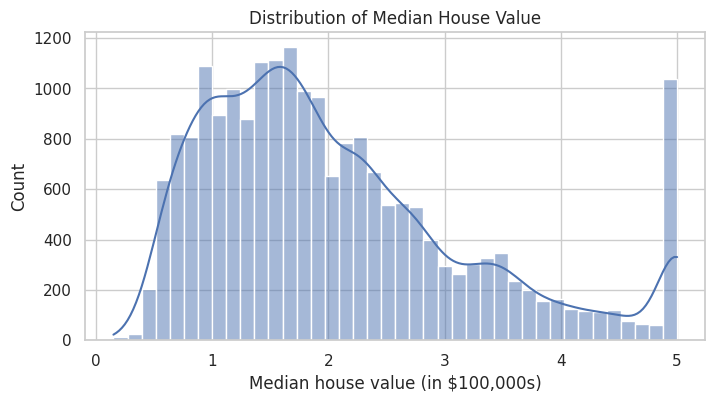

In [3]:
df.info()
display(df.describe().T)
print("Missing values:")
display(df.isnull().sum())

plt.figure(figsize=(8, 4))
sns.histplot(df["median_house_value"], bins=40, kde=True)
plt.title("Distribution of Median House Value")
plt.xlabel("Median house value (in $100,000s)")
plt.show()


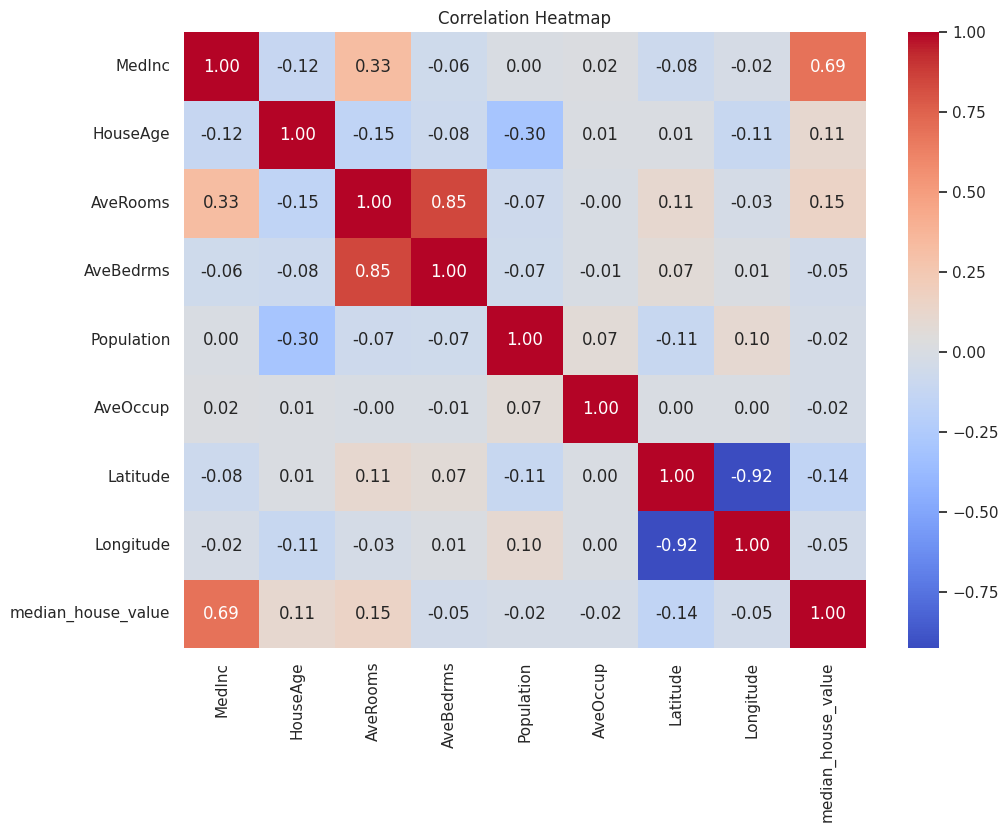

,median_house_value
MedInc,0.688075
AveRooms,0.151948
Latitude,-0.144160
HouseAge,0.105623
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737


In [4]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

display(df.corr(numeric_only=True)["median_house_value"].drop("median_house_value").sort_values(key=abs, ascending=False))


In [5]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (16512, 8) Test: (4128, 8)


In [6]:
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)
print("Missing values after imputation:", X_train_imp.isnull().sum().sum())


Missing values after imputation: 0


In [7]:
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
train_array = poly.fit_transform(X_train_imp)
test_array = poly.transform(X_test_imp)
feature_names = poly.get_feature_names_out(X.columns)

X_train_inter = pd.DataFrame(train_array, columns=feature_names, index=X_train.index)
X_test_inter = pd.DataFrame(test_array, columns=feature_names, index=X_test.index)

print("Original features:", X_train_imp.shape[1])
print("After interaction engineering:", X_train_inter.shape[1])
display(X_train_inter.head())


Original features: 8
After interaction engineering: 36


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedInc HouseAge,MedInc AveRooms,...,AveBedrms Population,AveBedrms AveOccup,AveBedrms Latitude,AveBedrms Longitude,Population AveOccup,Population Latitude,Population Longitude,AveOccup Latitude,AveOccup Longitude,Latitude Longitude
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03,107.5668,16.355553,...,2314.767255,3.715517,32.920016,-117.781396,8491.171750,75233.00,-269169.00,120.759230,-432.052970,-3828.0513
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16,186.8125,17.055390,...,1367.880952,1.809366,35.154749,-123.005185,2283.857143,44373.78,-155262.24,58.695476,-205.373333,-3990.2632
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48,16.6252,23.465777,...,901.383929,2.682690,34.144226,-118.687143,2491.741071,31713.90,-110239.20,94.386607,-328.092857,-4175.8368
14265,1.9425,36.0,4.002817,1.033803,1418.0,3.994366,32.69,-117.11,69.9300,7.775472,...,1465.932394,4.129387,33.795014,-121.068648,5664.011268,46354.42,-166061.98,130.575831,-467.780225,-3828.3259
2271,3.5542,43.0,6.268421,1.134211,874.0,2.300000,36.78,-119.80,152.8306,22.279222,...,991.300000,2.608684,41.716263,-135.878421,2010.200000,32145.72,-104705.20,84.594000,-275.540000,-4406.2440


In [8]:
corr = X_train_inter.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]
selected_features = [col for col in X_train_inter.columns if col not in to_drop]

X_train_sel = X_train_inter[selected_features].copy()
X_test_sel = X_test_inter[selected_features].copy()

print("Removed highly correlated features:", len(to_drop))
print("Remaining features:", len(selected_features))
print("Some removed features:", to_drop[:15])


Removed highly correlated features: 18
Remaining features: 18
Some removed features: ['MedInc AveOccup', 'MedInc Latitude', 'MedInc Longitude', 'HouseAge AveOccup', 'HouseAge Latitude', 'HouseAge Longitude', 'AveRooms Latitude', 'AveRooms Longitude', 'AveBedrms Population', 'AveBedrms AveOccup', 'AveBedrms Latitude', 'AveBedrms Longitude', 'Population AveOccup', 'Population Latitude', 'Population Longitude']


In [9]:
# Sample rows to make VIF calculation faster
vif_sample = X_train_sel.sample(n=min(3000, len(X_train_sel)), random_state=RANDOM_STATE).reset_index(drop=True)
vif_df = pd.DataFrame({
    "Feature": vif_sample.columns,
    "VIF": [variance_inflation_factor(vif_sample.values, i) for i in range(vif_sample.shape[1])]
}).sort_values("VIF", ascending=False)
display(vif_df.head(15))


,Feature,VIF
13,HouseAge AveBedrms,124.926680
2,AveRooms,121.472926
12,HouseAge AveRooms,101.947539
3,AveBedrms,88.516298
16,AveRooms Population,40.007209
0,MedInc,36.054592
9,MedInc AveRooms,33.759947
4,Population,32.972244
1,HouseAge,32.947505
10,MedInc AveBedrms,30.870748


In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sel)
X_test_scaled = scaler.transform(X_test_sel)
print("Scaled train shape:", X_train_scaled.shape)


Scaled train shape: (16512, 18)


In [11]:
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

ridge = RidgeCV(alphas=np.logspace(-3, 3, 13), cv=5)
ridge.fit(X_train_scaled, y_train)

lasso = LassoCV(alphas=np.logspace(-4, 1, 30), cv=5, max_iter=20000, random_state=RANDOM_STATE)
lasso.fit(X_train_scaled, y_train)

print("Ridge selected alpha:", ridge.alpha_)
print("Lasso selected alpha:", lasso.alpha_)


Ridge selected alpha: 316.22776601683796
Lasso selected alpha: 0.005298316906283713


In [12]:
models = {"OLS": ols, "Ridge": ridge, "Lasso": lasso}
rows = []

for name, model in models.items():
    pred = model.predict(X_test_scaled)
    rows.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(rows).sort_values("RMSE")
display(results_df.round(4))


,Model,RMSE,MAE,R2
2,Lasso,0.7473,0.5297,0.5738
0,OLS,0.7607,0.5295,0.5584
1,Ridge,0.7757,0.5318,0.5408


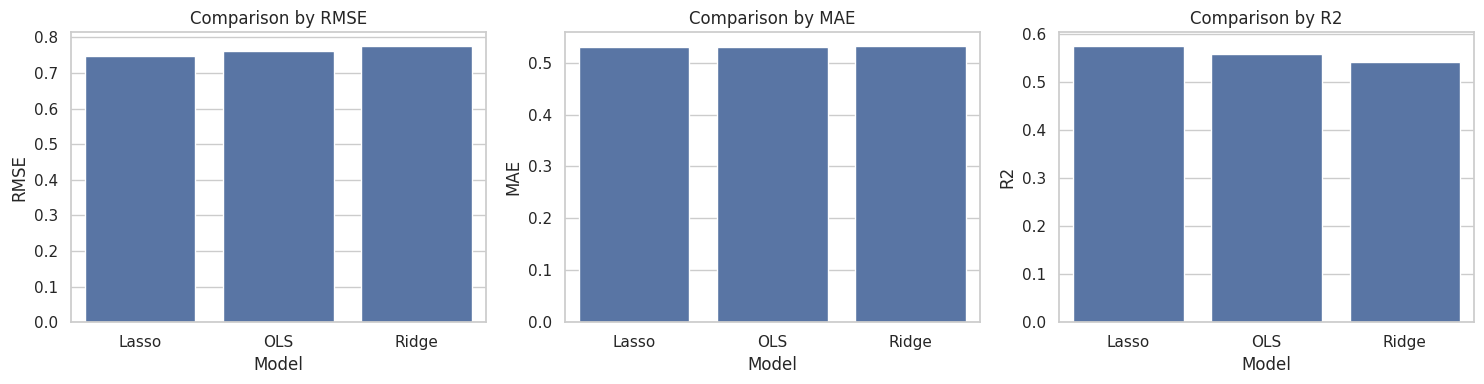

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    sns.barplot(data=results_df, x="Model", y=metric, ax=ax)
    ax.set_title(f"Comparison by {metric}")
plt.tight_layout()
plt.show()


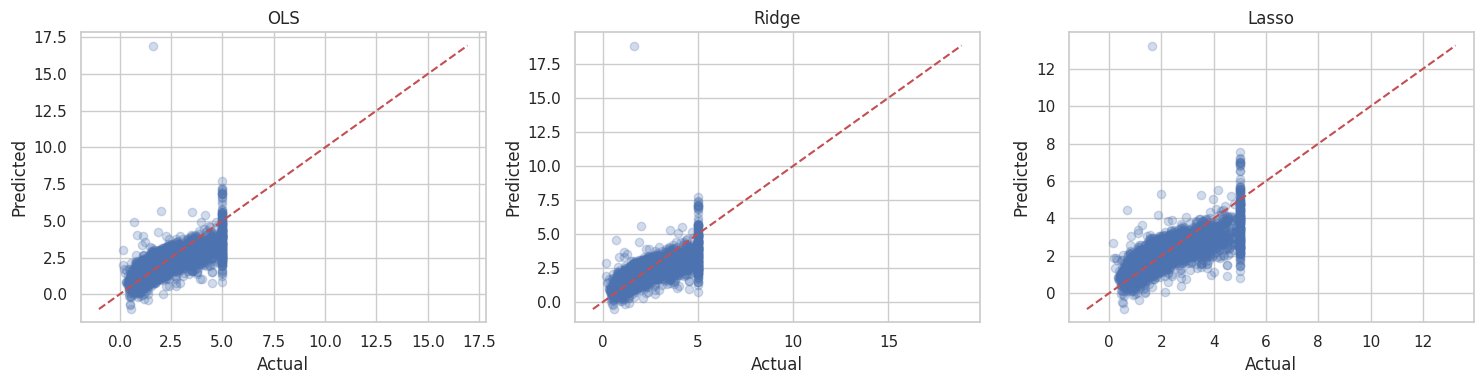

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test_scaled)
    ax.scatter(y_test, pred, alpha=0.25)
    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())
    ax.plot([low, high], [low, high], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
plt.tight_layout()
plt.show()


In [15]:
best = results_df.loc[results_df["RMSE"].idxmin()]
print("Best model based on lowest RMSE:", best["Model"])
display(best.to_frame("Value"))

print("Interpretation:")
print("- Lower RMSE and MAE indicate smaller prediction errors.")
print("- Higher R2 indicates better explained variance.")
print("- Ridge uses L2 regularization; Lasso uses L1 regularization.")


Best model based on lowest RMSE: Lasso


,Value
Model,Lasso
RMSE,0.747331
MAE,0.529676
R2,0.573794


Interpretation:
- Lower RMSE and MAE indicate smaller prediction errors.
- Higher R2 indicates better explained variance.
- Ridge uses L2 regularization; Lasso uses L1 regularization.
